# **Orange Vision: Comparación de YOLO11n, YOLO11m y RT-DETR**
### Fine-tuning en Google Colab con el dataset "Oranges in the field" (Mendeley Data)

Los tres modelos se entrenan y evalúan con las mismas imágenes y las mismas reglas:
1. **Datos**: subconjunto configurable (`N_IMAGENES`) de las 5025 imágenes, con todas las de interior y los demás entornos en proporción a su tamaño.
2. **División**: 20% de test bloqueado y 80% para entrenar (aprox. 70% train y 10% val). Todas las imágenes con el mismo ID quedan en la misma división.
3. **Fine-tuning**: Fase 1 con el *backbone* congelado y Fase 2 con toda la red descongelada y una tasa de aprendizaje 10 veces menor.
4. **Evaluación**: precisión, recall, F1, exactitud, mAP50, mAP50-95, parámetros, GFLOPs, épocas, tiempo y latencia medida, con media ± desviación entre semillas.

**Cómo ejecutarlo:** selecciona *Entorno de ejecución > Cambiar tipo > GPU T4* y luego *Ejecutar todas*. Los resultados se guardan en Google Drive. Si Colab se desconecta, vuelve a ejecutar todas las celdas: lo terminado se omite y lo interrumpido continúa desde `last.pt`.

Dataset: Lucas et al., *Oranges in the field*, Mendeley Data, https://doi.org/10.17632/93f32zgkxz.1 (licencia CC BY-NC 3.0).

In [ ]:
# 1. Librerías Básicas
%pip install -q ultralytics==8.4.175 torchmetrics pycocotools opencv-python seaborn

import os
import re
import gc
import sys
import hashlib
import shutil
import time
import json
import random
import urllib.request
from concurrent.futures import ThreadPoolExecutor
import joblib
import numpy as np
import pandas as pd
import torch
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

import ultralytics
from ultralytics import YOLO, RTDETR, settings
from ultralytics.data.utils import check_det_dataset
from ultralytics.utils.torch_utils import get_flops

# Métricas de detección
from torchmetrics.detection import MeanAveragePrecision

In [ ]:
# 2. Configuración del experimento: todos los ajustes están en esta celda
N_IMAGENES = 1000       # Cualquier tamaño hasta 5025; None = dataset completo
ENTORNOS = None         # None = los 9 entornos; ej. ['MS', 'AC', 'IN'] para restringirlos
ENTORNOS_COMPLETOS = ['IN']  # Se incluyen todas sus imágenes (interior: primer despliegue); [] = solo proporcional
FRACCION_TEST = 0.20    # Test bloqueado hasta la evaluación final
FRACCION_VAL = 0.10     # Sale del 80% restante, dejando aprox. 70% para train
SEMILLA_SPLIT = 42      # Mantiene la división reproducible
SEMILLAS = [0, 1, 2]    # Un entrenamiento completo por semilla

# 'freeze' congela el backbone completo de cada arquitectura en la Fase 1
MODELOS = {
    'YOLO11n': {'pesos': 'yolo11n.pt', 'freeze': 11},
    'YOLO11m': {'pesos': 'yolo11m.pt', 'freeze': 11},
    'RT-DETR': {'pesos': 'rtdetr-l.pt', 'freeze': 10},
}

IMGSZ = 640
OPTIMIZADOR = 'AdamW'
NBS = 64
BATCH_CANDIDATOS = [16, 8, 4]   # La prueba inicial elige el mayor que RT-DETR soporta

EPOCAS_FASE1, PACIENCIA_FASE1 = 30, 10
EPOCAS_FASE2, PACIENCIA_FASE2 = 70, 20

LR_CANDIDATOS = [1e-3, 3e-4, 1e-4]   # Barrido en Fase 1; la Fase 2 usa el ganador / 10
EPOCAS_BARRIDO = 15
EPOCAS_PRUEBA = 2

# Valores explícitos e iguales para los tres modelos
AUGMENTACION = dict(hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, degrees=0.0, translate=0.1, scale=0.5,
                    shear=0.0, perspective=0.0, flipud=0.0, fliplr=0.5, mosaic=1.0, close_mosaic=10,
                    mixup=0.0, cutmix=0.0, copy_paste=0.0)

N_BOOTSTRAP = 1000
MIN_IMAGENES_ENTORNO = 30   # Por debajo, el resultado del entorno se marca como no fiable
N_LATENCIA_GPU, N_LATENCIA_CPU, N_CALENTAMIENTO = 120, 30, 10
WORKERS = 2

In [ ]:
# 3. Entorno de ejecución y carpetas de resultados
EN_COLAB = 'google.colab' in sys.modules
HAY_GPU = torch.cuda.is_available()

if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive/MyDrive/Facultad/9no semestre/IA/Proyecto')
    if not HAY_GPU:
        raise RuntimeError('No hay GPU. Selecciona Entorno de ejecución > Cambiar tipo > GPU T4.')
    RAIZ_RESULTADOS = Path('/content/drive/MyDrive/orange_vision_comparacion')
    RAIZ_DATOS = Path('/content')
else:
    print('Aviso: ejecución fuera de Colab; los resultados se guardan en la carpeta local.')
    RAIZ_RESULTADOS = Path('resultados_comparacion')
    RAIZ_DATOS = Path('.')

DEVICE = 0 if HAY_GPU else 'cpu'
NOMBRE_GPU = torch.cuda.get_device_name(0) if HAY_GPU else 'sin GPU'

# Cada combinación de datos y ajustes de entrenamiento tiene su propia carpeta, así nunca se mezclan.
# SEMILLAS queda fuera para poder añadir semillas sin repetir lo ya entrenado.
ETIQUETA_DATOS = f"N{N_IMAGENES or 'todas'}_{'todos' if not ENTORNOS else '-'.join(sorted(ENTORNOS))}"
if ENTORNOS_COMPLETOS:
    ETIQUETA_DATOS += '_completos-' + '-'.join(sorted(ENTORNOS_COMPLETOS))
AJUSTES_ENTRENAMIENTO = dict(FRACCION_TEST=FRACCION_TEST, FRACCION_VAL=FRACCION_VAL, SEMILLA_SPLIT=SEMILLA_SPLIT, MODELOS=MODELOS,
                             IMGSZ=IMGSZ, OPTIMIZADOR=OPTIMIZADOR, NBS=NBS, BATCH_CANDIDATOS=BATCH_CANDIDATOS,
                             EPOCAS_FASE1=EPOCAS_FASE1, PACIENCIA_FASE1=PACIENCIA_FASE1, EPOCAS_FASE2=EPOCAS_FASE2,
                             PACIENCIA_FASE2=PACIENCIA_FASE2, LR_CANDIDATOS=LR_CANDIDATOS, EPOCAS_BARRIDO=EPOCAS_BARRIDO,
                             AUGMENTACION=AUGMENTACION)
HUELLA = hashlib.sha1(json.dumps(AJUSTES_ENTRENAMIENTO, sort_keys=True).encode()).hexdigest()[:8]
ETIQUETA = f'{ETIQUETA_DATOS}_cfg{HUELLA}'
BASE = (RAIZ_RESULTADOS / ETIQUETA).resolve()
RUNS = BASE / 'runs'
RESULTADOS = BASE / 'resultados'
CACHE_PRED = BASE / 'predicciones'
for carpeta in (RUNS, RESULTADOS, CACHE_PRED):
    carpeta.mkdir(parents=True, exist_ok=True)
(BASE / 'ajustes_entrenamiento.json').write_text(json.dumps(AJUSTES_ENTRENAMIENTO, indent=2))

print('Experimento:', ETIQUETA)
print('Resultados en:', BASE)
print('GPU:', NOMBRE_GPU, '| torch', torch.__version__, '| ultralytics', ultralytics.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Experimento: N1000_todos_completos-IN_cfg3f186cb6
Resultados en: /content/drive/MyDrive/orange_vision_comparacion/N1000_todos_completos-IN_cfg3f186cb6
GPU: Tesla T4 | torch 2.11.0+cu130 | ultralytics 8.4.175


In [ ]:
# 4. Configurar clases de interés para Inferencia Pura
# El modelo YOLO preentrenado en COCO incluye la clase 'orange' (ID 49 en COCO).
class_names = ['orange']
print('Clases objetivo iniciales para detección:', class_names)

Clases objetivo iniciales para detección: ['orange']


In [ ]:
# 5. Inferencia pura: YOLO preentrenado en COCO, sin entrenar con nuestros datos
modelo_base = YOLO('yolo11n.pt')

print('Total de clases que conoce YOLO COCO:', len(modelo_base.names))
for nombre in class_names:
    print(f'  {nombre}:', 'sí' if nombre in modelo_base.names.values() else 'NO')

Total de clases que conoce YOLO COCO: 80
  orange: sí


In [ ]:
# 6. Función para realizar predicciones filtrando por 'orange' (naranja)
def detectar_naranjas(modelo, ruta_imagen, conf_min=0.25):
    """
    Realiza inferencia sobre una imagen y muestra las detecciones de naranjas.
    """
    ruta_p = Path(ruta_imagen)
    if not ruta_p.exists():
        print(f"Error: La imagen '{ruta_imagen}' no existe.")
        return None

    # Inferencia con YOLO
    resultados = modelo.predict(ruta_imagen, conf=conf_min, verbose=False)[0]

    nombre_modelo = getattr(modelo, 'model_name', 'YOLO')
    print(f"\nResultados para {ruta_p.name} ({nombre_modelo}):")
    encontrado = False
    conteo = 0

    for caja in resultados.boxes:
        nombre_clase = resultados.names[int(caja.cls)]
        # Si el modelo tiene la clase 'orange', o si tiene solo 1 clase entrenada (dataset propio)
        if nombre_clase == 'orange' or len(resultados.names) == 1:
            encontrado = True
            conteo += 1
            conf = round(float(caja.conf), 3)
            coords = [round(x, 1) for x in caja.xyxy[0].tolist()]
            print(f"  [Naranja #{conteo}] Confianza: {conf} | Coordenadas: {coords}")

    if not encontrado:
        print("  No se detectaron naranjas en la imagen con la confianza mínima requerida.")
    else:
        print(f"  Total de naranjas detectadas: {conteo}")

    resultados.show()
    return resultados


Resultados para orange_sample.jpg (yolo11n.pt):
  [Naranja #1] Confianza: 0.692 | Coordenadas: [165.3, 165.9, 315.8, 317.9]
  [Naranja #2] Confianza: 0.687 | Coordenadas: [250.0, 250.6, 411.0, 411.9]
  [Naranja #3] Confianza: 0.683 | Coordenadas: [355.1, 145.3, 485.4, 276.1]
  Total de naranjas detectadas: 3


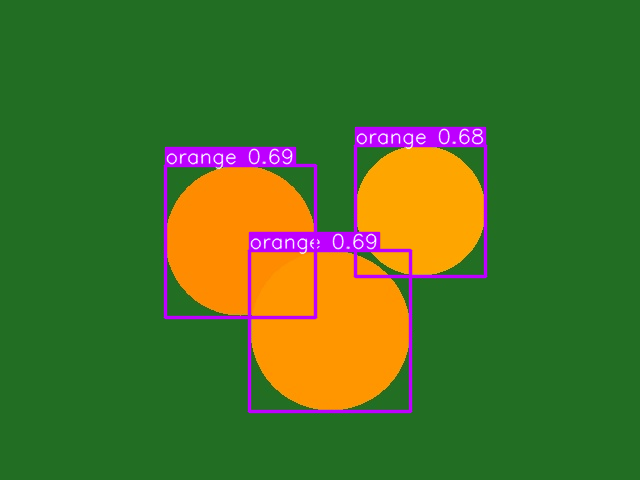

ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
depth: None
keypoints: None
masks: None
names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'po

In [ ]:
# 7. Detección con una foto usando el modelo base
ruta_prueba = 'orange_sample.jpg'

# Si no existe una foto local, generamos una imagen sintética de prueba
if not Path(ruta_prueba).exists():
    img_temp = np.zeros((480, 640, 3), dtype=np.uint8)
    img_temp[:] = (34, 110, 34)  # Fondo verdoso simulando follaje
    cv2.circle(img_temp, (240, 240), 75, (0, 140, 255), -1)  # Naranja 1
    cv2.circle(img_temp, (420, 210), 65, (0, 165, 255), -1)  # Naranja 2
    cv2.circle(img_temp, (330, 330), 80, (0, 150, 255), -1)  # Naranja 3
    cv2.imwrite(ruta_prueba, img_temp)
    print(f"Se ha creado una imagen de prueba temporal en: {ruta_prueba}")

detectar_naranjas(modelo_base, ruta_prueba, conf_min=0.25)

In [ ]:
# 8. Cargar datos: Dataset "Oranges in the field" (Mendeley Data)
# Referencia: https://data.mendeley.com/datasets/93f32zgkxz/1
# 5025 imágenes de 640x640 con etiquetas YOLO. Las dos primeras letras del archivo indican el entorno.

API_NARANJAS = 'https://data.mendeley.com/public-api/datasets/93f32zgkxz'
CABECERA = {'User-Agent': 'Mozilla/5.0'}
PATRON_ARCHIVO = re.compile(r'^(([A-Z]{2})\d+)_(\d{4}-\d{2}-\d{2})_(\d+)\.jpg$')
NOMBRES_ENTORNO = {
    'MS': 'Mañana, soleado', 'AC': 'Tarde, nublado', 'AS': 'Tarde, soleado',
    'ES': 'Atardecer, soleado', 'MC': 'Mañana, nublado', 'NI': 'Noche',
    'IN': 'Interior', 'EC': 'Atardecer, nublado', 'AR': 'Tarde, lluvia',
}
class_names = ['orange']


def consultar_archivos():
    """Devuelve una fila por imagen, con entorno, ID y URLs de descarga."""
    req = urllib.request.Request(API_NARANJAS, headers=CABECERA)
    with urllib.request.urlopen(req, timeout=60) as r:
        archivos = json.loads(r.read().decode('utf-8'))['files']
    etiquetas = {a['filename'][:-4]: a for a in archivos if a['filename'].endswith('.txt')}
    filas = []
    for a in archivos:
        m = PATRON_ARCHIVO.match(a['filename'])
        if m and a['filename'][:-4] in etiquetas:
            filas.append({'archivo': a['filename'], 'id': m[1], 'entorno': m[2], 'fecha': m[3],
                          'url_img': a['content_details']['download_url'],
                          'url_lbl': etiquetas[a['filename'][:-4]]['content_details']['download_url']})
    return pd.DataFrame(filas).sort_values('archivo').reset_index(drop=True)


def asignar_splits(df, frac_test, frac_val, semilla):
    """Asigna cada ID a un split usando todo el dataset, por entorno y sin separar un mismo ID."""
    fracciones = {'train': 1 - frac_test - frac_val, 'val': frac_val, 'test': frac_test}
    split_por_id = {}
    for entorno, sub in df.groupby('entorno'):
        tamanos = sub.groupby('id').size().to_dict()
        ids = sorted(tamanos)
        random.Random(f'{semilla}-{entorno}').shuffle(ids)
        ids.sort(key=lambda i: -tamanos[i])  # Los IDs grandes primero, para repartir mejor
        objetivo = {s: f * len(sub) for s, f in fracciones.items()}
        actual = dict.fromkeys(fracciones, 0)
        for i in ids:
            split = max(fracciones, key=lambda s: objetivo[s] - actual[s])
            split_por_id[i] = split
            actual[split] += tamanos[i]
    return df.assign(split=df['id'].map(split_por_id))


def seleccionar(df, n, entornos, frac_test, frac_val, semilla, completos=()):
    """Toma n imágenes: todas las de 'completos' y el resto proporcional por entorno.
    Un n mayor contiene todas las imágenes de un n menor."""
    if entornos:
        df = df[df['entorno'].isin(entornos)]
    if n is None or n >= len(df):  # Todas las imágenes, con los splits ya asignados
        return df.sort_values(['split', 'archivo']).reset_index(drop=True)
    total = n
    n_test, n_val = round(total * frac_test), round(total * frac_val)
    objetivos = {'train': total - n_test - n_val, 'val': n_val, 'test': n_test}
    partes = []
    for split, n_split in objetivos.items():
        del_split = df[df['split'] == split]
        fijas = del_split[del_split['entorno'].isin(completos)].to_dict('records')
        if len(fijas) > n_split:
            print(f'Aviso: {split} supera su objetivo de {n_split} imágenes por incluir {len(fijas)} de {list(completos)}.')
        filas = []
        for entorno, sub in del_split[~del_split['entorno'].isin(completos)].groupby('entorno'):
            orden = sub.to_dict('records')
            rng = random.Random(f'{semilla}-{split}-{entorno}')
            rng.shuffle(orden)
            # Muestreo sistemático: cada entorno aparece repartido a lo largo de la prioridad
            for pos, fila in enumerate(orden):
                fila['_prioridad'] = (pos + 0.5) / len(orden)
                fila['_desempate'] = rng.random()
                filas.append(fila)
        filas.sort(key=lambda f: (f['_prioridad'], f['_desempate']))
        partes.extend(fijas + filas[:max(n_split - len(fijas), 0)])
    salida = pd.DataFrame(partes).drop(columns=['_prioridad', '_desempate'], errors='ignore')
    return salida.sort_values(['split', 'archivo']).reset_index(drop=True)


def comprobar_sin_fuga(df):
    compartidos = df.groupby('id')['split'].nunique()
    compartidos = compartidos[compartidos > 1]
    if len(compartidos):
        raise RuntimeError(f'IDs presentes en más de un split: {list(compartidos.index)[:10]}')


def descargar_archivo(url, destino):
    if destino.exists() and destino.stat().st_size > 0:
        return
    temporal = destino.with_name(destino.name + '.part')
    for intento in range(4):
        try:
            req = urllib.request.Request(url, headers=CABECERA)
            with urllib.request.urlopen(req, timeout=60) as r:
                temporal.write_bytes(r.read())
            temporal.replace(destino)
            return
        except Exception as e:
            if intento == 3:
                raise RuntimeError(f'No se pudo descargar {destino.name}: {e}')
            time.sleep(2 ** intento)


def preparar_dataset(seleccion, carpeta):
    trabajos = []
    for fila in seleccion.itertuples():
        for tipo, url, nombre in (('images', fila.url_img, fila.archivo),
                                  ('labels', fila.url_lbl, fila.archivo[:-4] + '.txt')):
            (carpeta / tipo / fila.split).mkdir(parents=True, exist_ok=True)
            trabajos.append((url, carpeta / tipo / fila.split / nombre))
    with ThreadPoolExecutor(max_workers=8) as pool:
        list(pool.map(lambda t: descargar_archivo(*t), trabajos))
    yaml_path = carpeta / 'data.yaml'
    yaml_path.write_text(f"path: {carpeta.resolve().as_posix()}\ntrain: images/train\nval: images/val\n"
                         "test: images/test\nnames:\n  0: orange\n", encoding='utf-8')
    return yaml_path


# --- Ejecución ---
tabla_completa = asignar_splits(consultar_archivos(), FRACCION_TEST, FRACCION_VAL, SEMILLA_SPLIT)
comprobar_sin_fuga(tabla_completa)
seleccion = seleccionar(tabla_completa, N_IMAGENES, ENTORNOS, FRACCION_TEST, FRACCION_VAL, SEMILLA_SPLIT, ENTORNOS_COMPLETOS)
comprobar_sin_fuga(seleccion)

# El manifiesto protege contra mezclar resultados de divisiones distintas
COLUMNAS_MANIFIESTO = ['archivo', 'id', 'entorno', 'fecha', 'split']
RUTA_MANIFIESTO = BASE / 'split_manifest.csv'
if RUTA_MANIFIESTO.exists():
    guardado = pd.read_csv(RUTA_MANIFIESTO)
    if not guardado.equals(seleccion[COLUMNAS_MANIFIESTO].astype(guardado.dtypes.to_dict())):
        raise RuntimeError(f'La división no coincide con {RUTA_MANIFIESTO}. Usa otra configuración o revisa ese archivo.')
else:
    seleccion[COLUMNAS_MANIFIESTO].to_csv(RUTA_MANIFIESTO, index=False)

CARPETA_DATASET = RAIZ_DATOS / f'dataset_comparacion_{ETIQUETA_DATOS}'
print(f'Descargando {len(seleccion)} imágenes a {CARPETA_DATASET} ...')
DATA = str(preparar_dataset(seleccion, CARPETA_DATASET))
info = check_det_dataset(DATA)
TEST = str(CARPETA_DATASET / 'images' / 'test')


def contar_cajas(fila):
    ruta = CARPETA_DATASET / 'labels' / fila['split'] / (fila['archivo'][:-4] + '.txt')
    return sum(1 for l in ruta.read_text().splitlines() if l.strip())


seleccion['cajas'] = seleccion.apply(contar_cajas, axis=1)
RESUMEN_DATOS = seleccion.groupby('split').agg(imagenes=('archivo', 'size'), cajas=('cajas', 'sum'), ids=('id', 'nunique'))
print('\nImágenes y cajas por split:')
print(RESUMEN_DATOS.to_string())
print('\nImágenes por entorno y split:')
print(pd.crosstab(seleccion['entorno'], seleccion['split'], margins=True).to_string())
print('\nDataset listo:', DATA)

Descargando 1000 imágenes a /content/dataset_comparacion_N1000_todos_completos-IN ...

Imágenes y cajas por split:
       imagenes  cajas  ids
split                      
test        200   1917  120
train       700   5315  278
val         100   1076   75

Imágenes por entorno y split:
split    test  train  val   All
entorno                        
AC         38    146   22   206
AR          0      2    0     2
AS         22     84   13   119
EC          1      5    0     6
ES          8     30    4    42
IN         27     30    0    57
MC          4     17    2    23
MS         97    373   57   527
NI          3     13    2    18
All       200    700  100  1000

Dataset listo: /content/dataset_comparacion_N1000_todos_completos-IN/data.yaml


In [ ]:
# 9. Configurar TensorBoard para monitoreo del entrenamiento
# Los entrenamientos anteriores se conservan: son los que permiten continuar tras una desconexión.
%load_ext tensorboard

settings.update({'tensorboard': True})

In [ ]:
# 10. Funciones de entrenamiento: omiten lo terminado y continúan lo interrumpido
def cargar_modelo(nombre, pesos):
    clase = RTDETR if nombre == 'RT-DETR' else YOLO
    return clase(str(pesos))


def liberar_memoria():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def parametros_comunes(batch, amp):
    return dict(data=DATA, imgsz=IMGSZ, batch=batch, nbs=NBS, optimizer=OPTIMIZADOR, amp=amp, device=DEVICE,
                workers=WORKERS, deterministic=True, cos_lr=False, plots=True, verbose=False, **AUGMENTACION)


def entrenar(nombre_run, modelo_nombre, pesos, **params):
    """Entrena una vez y devuelve la carpeta del run. Guarda el batch realmente usado."""
    carpeta = RUNS / nombre_run
    marcador = carpeta / 'terminado.json'
    if marcador.exists():
        print(f'Omitido (ya terminado): {nombre_run}')
        return carpeta

    ultimo = carpeta / 'weights' / 'last.pt'
    real = {}

    def capturar_batch(trainer):
        real['batch_real'] = trainer.batch_size

    def reiniciar_anclas(trainer):
        # Con TensorBoard activo, el trazado del grafo deja en RT-DETR anclas creadas en modo inferencia,
        # que hacen fallar el entrenamiento. Vaciar 'shapes' obliga a generarlas de nuevo.
        cabeza = trainer.model.model[-1]
        if hasattr(cabeza, 'shapes'):
            cabeza.shapes = []

    if ultimo.exists():
        print(f'Continuando: {nombre_run}')
        modelo = cargar_modelo(modelo_nombre, ultimo)
        modelo.add_callback('on_train_end', capturar_batch)
        modelo.add_callback('on_train_epoch_start', reiniciar_anclas)
        try:
            modelo.train(resume=True)
        except AssertionError as e:
            if 'nothing to resume' not in str(e):  # El run acabó justo antes de crear el marcador
                raise
    else:
        print(f'Entrenando: {nombre_run}')
        shutil.rmtree(carpeta, ignore_errors=True)
        modelo = cargar_modelo(modelo_nombre, pesos)
        modelo.add_callback('on_train_end', capturar_batch)
        modelo.add_callback('on_train_epoch_start', reiniciar_anclas)
        modelo.train(project=str(RUNS), name=nombre_run, exist_ok=True, **params)

    marcador.write_text(json.dumps({'batch_real': real.get('batch_real'), 'batch_pedido': params.get('batch')}))
    del modelo
    liberar_memoria()
    return carpeta


def leer_run(carpeta):
    df = pd.read_csv(carpeta / 'results.csv')
    df.columns = df.columns.str.strip()
    mejor = df.loc[df['metrics/mAP50-95(B)'].idxmax()]
    perdidas = [c for c in df.columns if c.startswith('train/')]
    return {'epocas': int(df['epoch'].max()), 'mejor_epoca': int(mejor['epoch']),
            'map_val': float(mejor['metrics/mAP50-95(B)']), 'tiempo_s': float(df['time'].iloc[-1]),
            'tiene_nan': bool(df[perdidas].isna().any().any() or np.isinf(df[perdidas].to_numpy()).any()),
            'seg_por_epoca': float(df['time'].diff().iloc[-1]) if len(df) > 1 else float(df['time'].iloc[-1])}

In [ ]:
# 11. Prueba inicial: elige un único batch y amp para todos y proyecta el tiempo total
# Se prueba con toda la red descongelada, el caso de mayor consumo de memoria.
RUTA_AJUSTES = BASE / 'ajustes.json'


def probar(nombre, batch, amp):
    run = f'prueba_{nombre}_b{batch}_amp{int(amp)}'
    try:
        carpeta = entrenar(run, nombre, MODELOS[nombre]['pesos'], epochs=EPOCAS_PRUEBA, patience=EPOCAS_PRUEBA,
                           lr0=1e-4, freeze=0, warmup_epochs=0, seed=0, **parametros_comunes(batch, amp))
    except RuntimeError as e:
        if 'out of memory' in str(e).lower():
            liberar_memoria()
            return None
        raise
    marcador = json.loads((carpeta / 'terminado.json').read_text())
    if marcador['batch_real'] not in (None, batch):  # Ultralytics redujo el batch por falta de memoria
        return None
    return leer_run(carpeta)


def buscar_ajustes():
    for amp in (True, False):
        batch, resultados = None, {}
        for candidato in BATCH_CANDIDATOS:
            resultados['RT-DETR'] = probar('RT-DETR', candidato, amp)
            if resultados['RT-DETR'] is not None:
                batch = candidato
                break
        if batch is None:
            raise RuntimeError('RT-DETR no cabe en memoria con ningún batch de BATCH_CANDIDATOS.')
        for nombre in MODELOS:
            if nombre not in resultados:
                resultados[nombre] = probar(nombre, batch, amp)
                if resultados[nombre] is None:
                    raise RuntimeError(f'{nombre} no cabe en memoria con batch={batch}.')
        if not any(r['tiene_nan'] for r in resultados.values()):
            return {'batch': batch, 'amp': amp, 'gpu': NOMBRE_GPU,
                    'seg_por_epoca': {n: r['seg_por_epoca'] for n, r in resultados.items()}}
        print(f'Pérdidas NaN con amp={amp}; se repite la prueba sin precisión mixta.')
    raise RuntimeError('Aparecen pérdidas NaN también sin precisión mixta. Revisa los datos y la versión.')


if RUTA_AJUSTES.exists():
    ajustes = json.loads(RUTA_AJUSTES.read_text())
else:
    ajustes = buscar_ajustes()
    RUTA_AJUSTES.write_text(json.dumps(ajustes, indent=2))

BATCH, AMP = ajustes['batch'], ajustes['amp']
print(f"\nBatch para todos los modelos: {BATCH} | Precisión mixta: {AMP} | GPU de la prueba: {ajustes['gpu']}")

epocas_max = EPOCAS_BARRIDO * len(LR_CANDIDATOS) + len(SEMILLAS) * (EPOCAS_FASE1 + EPOCAS_FASE2)
proyeccion = pd.DataFrame([{'Modelo': n, 'Seg/época': round(s, 1), 'Épocas máximas': epocas_max,
                            'Horas máximas': round(s * epocas_max / 3600, 1)}
                           for n, s in ajustes['seg_por_epoca'].items()])
print(proyeccion.to_string(index=False))
print(f"Total máximo proyectado: {proyeccion['Horas máximas'].sum():.1f} h (sin contar la parada temprana).")
print('Si no cabe en una sesión, vuelve a ejecutar todo en otra: los runs terminados se omiten.')

Entrenando: prueba_RT-DETR_b16_amp1
New https://pypi.org/project/ultralytics/8.4.202 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_comparacion_N1000_todos_completos-IN/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=0, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_rat

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(


TensorBoard: model graph visualization added ✅
Using 700 train, 100 val images for fraction=1.0 at imgsz=640
Using 2 dataloader workers
Logging results to /content/drive/MyDrive/orange_vision_comparacion/N1000_todos_completos-IN_cfg3f186cb6/runs/prueba_RT-DETR_b16_amp1
Starting training for 2 epochs...
Closing dataloader mosaic
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
        1/2        12G     0.9318     0.9948     0.3883         43        640: 0% ──────────── 0/44  6.5s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        1/2      12.6G     0.7995     0.8107     0.2309         90        640: 100% ━━━━━━━━━━━━ 44/44 1.1s/it 49.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.4s/it 5.5s
                   all        100       1074      0.749      0.666      0.705      0.363

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        2/2      12.5G     0.7036     0.5168     0.1925         90        640: 100% ━━━━━━━━━━━━ 44/44 1.0s/it 44.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.0it/s 2.0s
                   all        100       1074      0.793      0.719      0.772      0.399

2 epochs completed in 0.034 hours.
Optimizer stripped from /content/drive/MyDrive/orange_vision_comparacion/N1000_todos_completos-IN_cfg3f186cb6/runs/prueba_RT-DETR_b16_amp1/weights/last.pt, 66.2MB
Optimizer stripped from /content/drive/MyDrive/orange_vision_comparacion/N1000_todos_completos-IN_cfg3f186cb6/runs/prueba_RT-DETR_b16_amp1/weights/best.pt, 66.2MB

Validating /content/drive/MyDrive/orange_vision_comparacion/N1000_todos_completos-IN_cfg3f186cb6/runs/prueba_RT-DETR_b16_amp1/weights/best.pt...
Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary (fused): 315 layers, 31,985,795 parameters, 0 gradients, 10

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        1/2      2.35G      1.986      3.453      1.597         90        640: 100% ━━━━━━━━━━━━ 44/44 2.3it/s 19.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.1it/s 3.5s
                   all        100       1074      0.675      0.559        0.6      0.287

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        2/2      2.79G      1.785      1.477      1.402         90        640: 100% ━━━━━━━━━━━━ 44/44 4.2it/s 10.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.4it/s 1.7s
                   all        100       1074      0.739      0.605      0.665       0.33

2 epochs completed in 0.011 hours.
Optimizer stripped from /content/drive/MyDrive/orange_vision_comparacion/N1000_todos_completos-IN_cfg3f186cb6/runs/prueba_YOLO11n_b16_amp1/weigh

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(


albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        1/2      7.96G      1.941      2.794      1.571         90        640: 100% ━━━━━━━━━━━━ 44/44 1.9it/s 22.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.5it/s 2.6s
                   all        100       1074      0.681      0.615      0.634      0.324

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        2/2      7.99G      1.639      1.124      1.316         90        640: 100% ━━━━━━━━━━━━ 44/44 2.1it/s 21.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.5it/s 1.6s
                   all        100       1074      0.809

In [ ]:
# 12. Barrido de tasa de aprendizaje: mismo proceso para cada modelo, decidido solo con validación
RUTA_BARRIDO = BASE / 'barrido_lr.csv'
filas_barrido = []
for nombre, cfg in MODELOS.items():
    for lr in LR_CANDIDATOS:
        carpeta = entrenar(f'barrido_{nombre}_lr{lr:g}', nombre, cfg['pesos'], epochs=EPOCAS_BARRIDO,
                           patience=EPOCAS_BARRIDO, lr0=lr, freeze=cfg['freeze'], warmup_epochs=3, seed=SEMILLAS[0],
                           **parametros_comunes(BATCH, AMP))
        filas_barrido.append({'Modelo': nombre, 'lr0': lr, 'mAP50-95 val': leer_run(carpeta)['map_val']})

tabla_barrido = pd.DataFrame(filas_barrido)
tabla_barrido.to_csv(RUTA_BARRIDO, index=False)
print(tabla_barrido.round(4).to_string(index=False))

LR_ELEGIDO = {n: float(g.loc[g['mAP50-95 val'].idxmax(), 'lr0']) for n, g in tabla_barrido.groupby('Modelo')}
print('\nTasa elegida por modelo (Fase 1):', LR_ELEGIDO)

Entrenando: barrido_YOLO11n_lr0.001
New https://pypi.org/project/ultralytics/8.4.202 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_comparacion_N1000_todos_completos-IN/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=11, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ra

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/15      1.32G      1.833      1.849      1.398         86        640: 100% ━━━━━━━━━━━━ 44/44 3.1it/s 14.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.3it/s 3.0s
                   all        100       1074      0.587       0.48      0.507      0.233

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/15      1.76G      1.799      1.374       1.35        237        640: 100% ━━━━━━━━━━━━ 44/44 3.8it/s 11.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.2it/s 1.8s
                   all        100       1074      0.699      0.543      0.602      0.266

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/15      1.76G      1.721      1.346      1.316        101        640: 100% ━━━━━━━━━━━━ 44/4

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/15      1.32G       1.83      1.867      1.393         86        640: 100% ━━━━━━━━━━━━ 44/44 3.4it/s 12.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.0it/s 3.9s
                   all        100       1074       0.66      0.485      0.508      0.248

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/15      1.76G      1.753      1.372      1.343        237        640: 100% ━━━━━━━━━━━━ 44/44 4.7it/s 9.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.5it/s 2.7s
                   all        100       1074      0.756      0.583      0.652      0.323

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/15      1.76G      1.685      1.301      1.292        101        640: 100% ━━━━━━━━━━━━ 44/44

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(


... (99 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      14/15      7.04G     0.6456     0.8343     0.1541         56        640: 100% ━━━━━━━━━━━━ 44/44 1.2it/s 36.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.9it/s 2.1s
                   all        100       1074      0.216      0.568      0.215      0.114

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      15/15      7.04G     0.5507     0.8626     0.1242         77        640: 0% ──────────── 0/44  0.9s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      15/15      7.04G     0.6398     0.8398     0.1559         52        640: 100% ━━━━━━━━━━━━ 44/44 1.2it/s 36.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.0it/s 2.0s
                   all        100       1074      0.215      0.571      0.213      0.113

15 epochs completed in 0.189 hours.
Optimizer stripped from /content/drive/MyDrive/orange_vision_comparacion/N1000_todos_completos-IN_cfg3f186cb6/runs/barrido_RT-DETR_lr0.0001/weights/last.pt, 66.2MB
Optimizer stripped from /content/drive/MyDrive/orange_vision_comparacion/N1000_todos_completos-IN_cfg3f186cb6/runs/barrido_RT-DETR_lr0.0001/weights/best.pt, 66.2MB

Validating /content/drive/MyDrive/orange_vision_comparacion/N1000_todos_completos-IN_cfg3f186cb6/runs/barrido_RT-DETR_lr0.0001/weights/best.pt...
Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary (fused): 315 layers, 31,985,795 parameters, 0 gradients

In [ ]:
# 13. Entrenamiento: Fase 1 (backbone congelado) y Fase 2 (fine-tuning de toda la red)
for nombre, cfg in MODELOS.items():
    for semilla in SEMILLAS:
        fase1 = entrenar(f'f1_{nombre}_s{semilla}', nombre, cfg['pesos'], epochs=EPOCAS_FASE1, patience=PACIENCIA_FASE1,
                         lr0=LR_ELEGIDO[nombre], freeze=cfg['freeze'], warmup_epochs=3, seed=semilla,
                         **parametros_comunes(BATCH, AMP))
        entrenar(f'f2_{nombre}_s{semilla}', nombre, fase1 / 'weights' / 'best.pt', epochs=EPOCAS_FASE2,
                 patience=PACIENCIA_FASE2, lr0=LR_ELEGIDO[nombre] / 10, freeze=0, warmup_epochs=0, seed=semilla,
                 **parametros_comunes(BATCH, AMP))
print('Todos los entrenamientos han terminado.')

Entrenando: f1_YOLO11n_s0
New https://pypi.org/project/ultralytics/8.4.202 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_comparacion_N1000_todos_completos-IN/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=11, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/30      1.32G      1.833      1.849      1.398         86        640: 100% ━━━━━━━━━━━━ 44/44 3.1it/s 14.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.4it/s 2.8s
                   all        100       1074      0.587       0.48      0.507      0.233

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/30      1.76G      1.801      1.376      1.349        237        640: 100% ━━━━━━━━━━━━ 44/44 4.3it/s 10.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.5it/s 2.6s
                   all        100       1074      0.701      0.524      0.586      0.262

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      1.76G      1.727      1.347      1.312        101        640: 100% ━━━━━━━━━━━━ 44/4

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/70      2.37G      1.567      1.258      1.217         86        640: 100% ━━━━━━━━━━━━ 44/44 2.9it/s 15.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.7it/s 2.3s
                   all        100       1074      0.777      0.694      0.747      0.402

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/70      2.81G      1.556      1.088      1.207        237        640: 100% ━━━━━━━━━━━━ 44/44 3.5it/s 12.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 3.5it/s 1.2s
                   all        100       1074      0.822      0.679      0.763       0.41

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/70      2.81G      1.488      1.031       1.17        101        640: 100% ━━━━━━━━━━━━ 44/4

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(


... (15 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/30      3.64G       1.71      1.473      1.315         56        640: 100% ━━━━━━━━━━━━ 44/44 2.7it/s 16.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.7it/s 2.3s
                   all        100       1074      0.787      0.638       0.72      0.365

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/30      5.81G      1.603      1.075      1.233        172        640: 100% ━━━━━━━━━━━━ 44/44 3.1it/s 14.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.6it/s 1.5s
                   all        100       1074      0.833      0.658      0.754      0.391

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      5.83G      1.575      1.044      1.227         87        640: 100% ━━━━━━━━━━━━ 44/4

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/70      8.01G      1.421     0.9202      1.136         56        640: 100% ━━━━━━━━━━━━ 44/44 1.9it/s 22.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.8it/s 2.2s
                   all        100       1074      0.846      0.717      0.805       0.44

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/70      8.01G      1.374     0.8301      1.122        172        640: 100% ━━━━━━━━━━━━ 44/44 2.1it/s 20.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.1it/s 1.9s
                   all        100       1074      0.873      0.712      0.804       0.44

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/70      8.04G       1.33     0.7911      1.106         87        640: 100% ━━━━━━━━━━━━ 44/4

In [ ]:
# 14. Visualizar y contrastar las curvas de pérdida y métricas en TensorBoard
%tensorboard --logdir "{RUNS}"

In [ ]:
# 15. Funciones de evaluación: el mismo código para todos los modelos
UMBRALES_IOU = np.linspace(0.5, 0.95, 10)
PUNTOS_RECALL = np.linspace(0, 1, 101)


def rutas_split(split):
    sub = seleccion[seleccion['split'] == split]
    return [CARPETA_DATASET / 'images' / split / a for a in sub['archivo']]


def leer_cajas_reales(ruta_img, alto, ancho):
    ruta = Path(str(ruta_img).replace(os.sep + 'images' + os.sep, os.sep + 'labels' + os.sep)).with_suffix('.txt')
    e = np.loadtxt(ruta, ndmin=2) if ruta.exists() and ruta.read_text().strip() else np.zeros((0, 5))
    return np.c_[e[:, 1] - e[:, 3] / 2, e[:, 2] - e[:, 4] / 2,
                 e[:, 1] + e[:, 3] / 2, e[:, 2] + e[:, 4] / 2] * [ancho, alto, ancho, alto]


def predecir(run, nombre, split):
    """Predicciones con conf baja, guardadas en Drive para no repetirlas."""
    cache = CACHE_PRED / f'{run}_{split}.joblib'
    if cache.exists():
        return joblib.load(cache)
    modelo = cargar_modelo(nombre, RUNS / run / 'weights' / 'best.pt')
    salida = {}
    for ruta in rutas_split(split):
        r = modelo.predict(str(ruta), conf=0.001, iou=0.7, max_det=300, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
        salida[ruta.name] = {'cajas': r.boxes.xyxy.cpu().numpy().astype(float), 'scores': r.boxes.conf.cpu().numpy().astype(float),
                             'reales': leer_cajas_reales(ruta, *r.orig_shape).astype(float)}
    joblib.dump(salida, cache)
    del modelo
    liberar_memoria()
    return salida


def matriz_iou(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1, y1 = np.maximum(a[:, None, 0], b[:, 0]), np.maximum(a[:, None, 1], b[:, 1])
    x2, y2 = np.minimum(a[:, None, 2], b[:, 2]), np.minimum(a[:, None, 3], b[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b - inter + 1e-9)


def preparar_evaluacion(preds):
    """Empareja cada predicción con una caja real por imagen (criterio COCO) para cada umbral de IoU."""
    nombres = sorted(preds)
    img, scores, tp = [], [], []
    n_reales = np.zeros(len(nombres))
    for i, nombre in enumerate(nombres):
        p = preds[nombre]
        orden = np.argsort(-p['scores'], kind='mergesort')
        cajas, s = p['cajas'][orden], p['scores'][orden]
        n_reales[i] = len(p['reales'])
        ious = matriz_iou(cajas, p['reales'])
        aciertos = np.zeros((len(cajas), len(UMBRALES_IOU)), dtype=bool)
        for t, umbral in enumerate(UMBRALES_IOU):
            libre = np.ones(len(p['reales']), dtype=bool)
            for d in range(len(cajas)):
                if not libre.any():
                    break
                fila = np.where(libre, ious[d], -1)
                mejor = fila.argmax()
                if fila[mejor] >= umbral:
                    aciertos[d, t] = True
                    libre[mejor] = False
        img.append(np.full(len(cajas), i))
        scores.append(s)
        tp.append(aciertos)
    img, scores, tp = np.concatenate(img), np.concatenate(scores), np.concatenate(tp)
    orden = np.argsort(-scores, kind='mergesort')
    return {'nombres': nombres, 'img': img[orden], 'scores': scores[orden], 'tp': tp[orden], 'n_reales': n_reales}


def ap_ponderado(ev, columna, pesos):
    """AP de 101 puntos. 'pesos' indica cuántas veces cuenta cada imagen."""
    total = (ev['n_reales'] * pesos).sum()
    if total == 0 or len(ev['scores']) == 0:
        return float('nan') if total == 0 else 0.0
    w = pesos[ev['img']]
    verdaderos = np.cumsum(ev['tp'][:, columna] * w)
    falsos = np.cumsum(~ev['tp'][:, columna] * w)
    recall = verdaderos / total
    precision = verdaderos / np.maximum(verdaderos + falsos, 1e-12)
    envolvente = np.maximum.accumulate(precision[::-1])[::-1]
    pos = np.searchsorted(recall, PUNTOS_RECALL, side='left')
    return float(np.where(pos < len(envolvente), envolvente[np.minimum(pos, len(envolvente) - 1)], 0).mean())


def map_50(ev, pesos):
    return ap_ponderado(ev, 0, pesos)


def map_50_95(ev, pesos):
    return float(np.mean([ap_ponderado(ev, c, pesos) for c in range(len(UMBRALES_IOU))]))


def conteos(ev, umbral, pesos):
    """TP, FP y FN con IoU 0.5 a un umbral de confianza."""
    dentro = ev['scores'] >= umbral
    w = pesos[ev['img'][dentro]]
    tp = float((ev['tp'][dentro, 0] * w).sum())
    fp = float((~ev['tp'][dentro, 0] * w).sum())
    return tp, fp, float((ev['n_reales'] * pesos).sum() - tp)


def metricas_umbral(tp, fp, fn):
    return {'Precisión': tp / max(tp + fp, 1e-12), 'Recall': tp / max(tp + fn, 1e-12),
            'F1': 2 * tp / max(2 * tp + fp + fn, 1e-12), 'Exactitud': tp / max(tp + fp + fn, 1e-12)}


def umbral_mejor_f1(ev):
    """Umbral de confianza con el mejor F1. Se calcula solo con validación."""
    if len(ev['scores']) == 0:
        return 0.25
    tp = np.cumsum(ev['tp'][:, 0])
    fp = np.cumsum(~ev['tp'][:, 0])
    f1 = 2 * tp / np.maximum(tp + fp + ev['n_reales'].sum(), 1e-12)
    return float(ev['scores'][f1.argmax()])


def comprobar_con_torchmetrics(preds):
    """Compara el mAP propio con torchmetrics, usando su límite fijo de 100 detecciones por imagen."""
    top = {}
    for nombre, p in preds.items():
        orden = np.argsort(-p['scores'], kind='mergesort')[:100]
        top[nombre] = {'cajas': p['cajas'][orden], 'scores': p['scores'][orden], 'reales': p['reales']}
    ev = preparar_evaluacion(top)
    pesos = np.ones(len(ev['nombres']))
    metrica = MeanAveragePrecision()
    for p in top.values():
        metrica.update([{'boxes': torch.tensor(p['cajas'], dtype=torch.float32), 'scores': torch.tensor(p['scores'], dtype=torch.float32),
                         'labels': torch.zeros(len(p['cajas']), dtype=torch.long)}],
                       [{'boxes': torch.tensor(p['reales'], dtype=torch.float32), 'labels': torch.zeros(len(p['reales']), dtype=torch.long)}])
    m = metrica.compute()
    return (map_50(ev, pesos), map_50_95(ev, pesos)), (float(m['map_50']), float(m['map']))


def medir_latencia(modelo, imagenes, dispositivo, umbral, n, calentamiento):
    tiempos = []
    for i in range(n + calentamiento):
        imagen = imagenes[i % len(imagenes)]
        if dispositivo != 'cpu':
            torch.cuda.synchronize()
        inicio = time.perf_counter()
        modelo.predict(imagen, conf=umbral, imgsz=IMGSZ, device=dispositivo, verbose=False)
        if dispositivo != 'cpu':
            torch.cuda.synchronize()
        if i >= calentamiento:
            tiempos.append((time.perf_counter() - inicio) * 1000)
    return float(np.median(tiempos))

In [ ]:
# 16. Evaluación final sobre test
# Exactitud = TP / (TP + FP + FN). La exactitud estándar necesita verdaderos negativos, que no existen en detección.
filas_semilla, evaluaciones, filas_entorno, COMPROBACIONES_MAP = [], {}, [], {}
for nombre in MODELOS:
    for semilla in SEMILLAS:
        run = f'f2_{nombre}_s{semilla}'
        if not (RUNS / run / 'terminado.json').exists():
            print(f'Aviso: falta {run}; no se incluye en los resultados.')
            continue
        ev_val = preparar_evaluacion(predecir(run, nombre, 'val'))
        preds_test = predecir(run, nombre, 'test')
        ev = preparar_evaluacion(preds_test)
        pesos = np.ones(len(ev['nombres']))
        umbral = umbral_mejor_f1(ev_val)
        fila = {'Modelo': nombre, 'Semilla': semilla, 'Umbral conf.': umbral,
                **metricas_umbral(*conteos(ev, umbral, pesos)), 'mAP50': map_50(ev, pesos), 'mAP50-95': map_50_95(ev, pesos),
                'mAP50-95 val': map_50_95(ev_val, np.ones(len(ev_val['nombres'])))}

        propio, externo = comprobar_con_torchmetrics(preds_test)
        if abs(propio[0] - externo[0]) > 0.01 or abs(propio[1] - externo[1]) > 0.01:
            print(f'Aviso {run}: mAP propio {propio} y torchmetrics {externo} difieren.')
        COMPROBACIONES_MAP[run] = (propio, externo)

        f1_info, f2_info = leer_run(RUNS / f'f1_{nombre}_s{semilla}'), leer_run(RUNS / run)
        for fase, datos in (('Fase 1', f1_info), ('Fase 2', f2_info)):
            fila[f'Épocas {fase}'] = datos['epocas']
            fila[f'Mejor época {fase}'] = datos['mejor_epoca']
            fila[f'Tiempo {fase} (min)'] = datos['tiempo_s'] / 60
        fila['Llegó al límite Fase 2'] = f2_info['epocas'] >= EPOCAS_FASE2
        for r in (f'f1_{nombre}_s{semilla}', run):
            marca = json.loads((RUNS / r / 'terminado.json').read_text())
            if marca['batch_real'] not in (None, BATCH):
                print(f"Aviso {r}: entrenó con batch={marca['batch_real']} en lugar de {BATCH}; la comparación deja de ser igual.")
        filas_semilla.append(fila)
        evaluaciones[(nombre, semilla)] = {'ev': ev, 'umbral': umbral, 'run': run}

        # Resultados por entorno
        entornos_img = np.array([n[:2] for n in ev['nombres']])
        for entorno in sorted(set(entornos_img)):
            p = (entornos_img == entorno).astype(float)
            filas_entorno.append({'Modelo': nombre, 'Semilla': semilla, 'Entorno': entorno, 'Imágenes': int(p.sum()),
                                  'Cajas': int((ev['n_reales'] * p).sum()), 'mAP50': map_50(ev, p),
                                  'Recall': metricas_umbral(*conteos(ev, umbral, p))['Recall']})

por_semilla = pd.DataFrame(filas_semilla)
por_semilla.to_csv(RESULTADOS / 'resultados_por_semilla.csv', index=False)

# Mejor semilla de cada modelo, elegida con validación y nunca con test
MEJOR_RUN = {n: g.loc[g['mAP50-95 val'].idxmax()] for n, g in por_semilla.groupby('Modelo')}
RUTAS_MEJORES = {n: RUNS / f"f2_{n}_s{int(MEJOR_RUN[n]['Semilla'])}" / 'weights' / 'best.pt' for n in MODELOS if n in MEJOR_RUN}

# Latencia real: todos los modelos en el mismo runtime; se guarda para no mezclar sesiones
RUTA_VELOCIDAD = RESULTADOS / 'velocidad.csv'
velocidad = pd.read_csv(RUTA_VELOCIDAD) if RUTA_VELOCIDAD.exists() else None
if velocidad is None or not set(RUTAS_MEJORES) <= set(velocidad['Modelo']):
    imagenes_test = [cv2.imread(str(r)) for r in rutas_split('test')]
    filas_vel = []
    for nombre, ruta in RUTAS_MEJORES.items():
        umbral = float(MEJOR_RUN[nombre]['Umbral conf.'])
        # Un modelo recién cargado por dispositivo, para medir cada uno en el dispositivo correcto
        cpu_ms = medir_latencia(cargar_modelo(nombre, ruta), imagenes_test, 'cpu', umbral, N_LATENCIA_CPU, N_CALENTAMIENTO)
        gpu_ms = (medir_latencia(cargar_modelo(nombre, ruta), imagenes_test, DEVICE, umbral, N_LATENCIA_GPU, N_CALENTAMIENTO)
                  if HAY_GPU else float('nan'))
        filas_vel.append({'Modelo': nombre, 'GPU (ms/imagen)': gpu_ms, 'GPU (FPS)': 1000 / gpu_ms, 'CPU (ms/imagen)': cpu_ms,
                          'CPU (FPS)': 1000 / cpu_ms, 'GPU usada': NOMBRE_GPU})
        liberar_memoria()
    velocidad = pd.DataFrame(filas_vel)
    velocidad.to_csv(RUTA_VELOCIDAD, index=False)

# Tamaño de cada modelo
filas_tamano = []
for nombre, ruta in RUTAS_MEJORES.items():
    modelo = cargar_modelo(nombre, ruta)
    filas_tamano.append({'Modelo': nombre, 'Parámetros (M)': sum(p.numel() for p in modelo.model.parameters()) / 1e6,
                         'GFLOPs': get_flops(modelo.model, IMGSZ), 'Archivo (MB)': ruta.stat().st_size / 1e6})
    del modelo
tamano = pd.DataFrame(filas_tamano)


def media_std(serie, decimales=3):
    if serie.count() < 2:
        return f'{serie.mean():.{decimales}f}'
    return f'{serie.mean():.{decimales}f} ± {serie.std():.{decimales}f}'


COLUMNAS_METRICAS = ['Precisión', 'Recall', 'F1', 'Exactitud', 'mAP50', 'mAP50-95']
filas_resumen = []
for nombre in MODELOS:
    g = por_semilla[por_semilla['Modelo'] == nombre]
    if g.empty:
        continue
    t, v = tamano[tamano['Modelo'] == nombre].iloc[0], velocidad[velocidad['Modelo'] == nombre].iloc[0]
    fila = {'Modelo': nombre, 'Semillas': len(g)}
    fila.update({c: media_std(g[c]) for c in COLUMNAS_METRICAS})
    fila.update({'Parámetros (M)': round(t['Parámetros (M)'], 2), 'GFLOPs': round(t['GFLOPs'], 1), 'Archivo (MB)': round(t['Archivo (MB)'], 1),
                 'Épocas máx. F1 / F2': f'{EPOCAS_FASE1} / {EPOCAS_FASE2}',
                 'Épocas ejecutadas F1': media_std(g['Épocas Fase 1'], 1), 'Mejor época F1': media_std(g['Mejor época Fase 1'], 1),
                 'Épocas ejecutadas F2': media_std(g['Épocas Fase 2'], 1), 'Mejor época F2': media_std(g['Mejor época Fase 2'], 1),
                 'Llegó al límite F2 (semillas)': int(g['Llegó al límite Fase 2'].sum()),
                 'Tiempo F1 + F2 (min)': media_std(g['Tiempo Fase 1 (min)'] + g['Tiempo Fase 2 (min)'], 1),
                 'lr0 F1': f'{LR_ELEGIDO[nombre]:g}', 'lr0 F2': f'{LR_ELEGIDO[nombre] / 10:g}', 'Optimizador': OPTIMIZADOR, 'Batch': BATCH,
                 'Capas congeladas F1': MODELOS[nombre]['freeze'], 'Tamaño imagen': IMGSZ, 'Umbral conf.': media_std(g['Umbral conf.']),
                 'GPU (ms/imagen)': round(v['GPU (ms/imagen)'], 1), 'GPU (FPS)': round(v['GPU (FPS)'], 1),
                 'CPU (ms/imagen)': round(v['CPU (ms/imagen)'], 1), 'CPU (FPS)': round(v['CPU (FPS)'], 1), 'GPU usada': v['GPU usada'],
                 'N imágenes': len(seleccion), 'Entornos': 'todos' if not ENTORNOS else ', '.join(ENTORNOS),
                 'Train (img / cajas)': '{imagenes} / {cajas}'.format(**RESUMEN_DATOS.loc['train']),
                 'Val (img / cajas)': '{imagenes} / {cajas}'.format(**RESUMEN_DATOS.loc['val']),
                 'Test (img / cajas)': '{imagenes} / {cajas}'.format(**RESUMEN_DATOS.loc['test'])})
    filas_resumen.append(fila)
resumen = pd.DataFrame(filas_resumen).set_index('Modelo')
resumen.to_csv(RESULTADOS / 'resumen_modelos.csv')
print('=== COMPARACIÓN DE MODELOS EN TEST ===')
print(resumen.T.to_string())

# Por entorno
por_entorno = pd.DataFrame(filas_entorno)
por_entorno_res = (por_entorno.groupby(['Entorno', 'Modelo'])
                   .agg(Imágenes=('Imágenes', 'first'), Cajas=('Cajas', 'first'), mAP50=('mAP50', 'mean'), Recall=('Recall', 'mean')).reset_index())
por_entorno_res['Descripción'] = por_entorno_res['Entorno'].map(NOMBRES_ENTORNO)
por_entorno_res['Fiable'] = por_entorno_res['Imágenes'] >= MIN_IMAGENES_ENTORNO
por_entorno_res.to_csv(RESULTADOS / 'resultados_por_entorno.csv', index=False)
print(f'\n=== POR ENTORNO (fiable = al menos {MIN_IMAGENES_ENTORNO} imágenes de test) ===')
print(por_entorno_res.round(3).to_string(index=False))

# Diferencias entre modelos: bootstrap pareado sobre las imágenes de test
modelos_ok = [n for n in MODELOS if (por_semilla['Modelo'] == n).any()]
n_imagenes_test = len(rutas_split('test'))
rng = np.random.default_rng(0)
remuestras = rng.multinomial(n_imagenes_test, np.full(n_imagenes_test, 1 / n_imagenes_test), size=N_BOOTSTRAP).astype(float)
FUNCIONES_BOOT = {'mAP50': map_50, 'mAP50-95': map_50_95}
valores = {}
for nombre in modelos_ok:
    claves = [k for k in evaluaciones if k[0] == nombre]
    for metrica, f in FUNCIONES_BOOT.items():
        valores[(nombre, metrica)] = np.mean([[f(evaluaciones[k]['ev'], w) for w in remuestras] for k in claves], axis=0)
    valores[(nombre, 'F1')] = np.mean([[metricas_umbral(*conteos(evaluaciones[k]['ev'], evaluaciones[k]['umbral'], w))['F1']
                                        for w in remuestras] for k in claves], axis=0)
filas_dif = []
for i, a in enumerate(modelos_ok):
    for b in modelos_ok[i + 1:]:
        for metrica in ['mAP50', 'mAP50-95', 'F1']:
            d = valores[(a, metrica)] - valores[(b, metrica)]
            bajo, alto = np.percentile(d, [2.5, 97.5])
            ganador = a if bajo > 0 else b if alto < 0 else 'Sin diferencia clara'
            filas_dif.append({'Comparación': f'{a} - {b}', 'Métrica': metrica, 'Diferencia media': d.mean(), 'IC95% inferior': bajo,
                              'IC95% superior': alto, 'Resultado': ganador})
comparaciones = pd.DataFrame(filas_dif)
comparaciones.to_csv(RESULTADOS / 'comparaciones_pareadas.csv', index=False)
print('\n=== DIFERENCIAS ENTRE MODELOS (solo hay ganador si el IC95% excluye el cero) ===')
print(comparaciones.round(3).to_string(index=False))

In [ ]:
# 17. Gráficos generados a partir de los resultados guardados
SUPERFICIE, TEXTO, TEXTO_SUAVE, REJILLA = '#fcfcfb', '#2b2b28', '#6b6b66', '#e6e6e2'
COLORES_MODELO = {'YOLO11n': '#2a78d6', 'YOLO11m': '#eb6834', 'RT-DETR': '#1baf7a'}  # Color fijo por modelo

plt.rcParams.update({'font.size': 10, 'font.family': 'sans-serif', 'figure.facecolor': SUPERFICIE, 'axes.facecolor': SUPERFICIE,
                     'axes.edgecolor': REJILLA, 'axes.labelcolor': TEXTO_SUAVE, 'text.color': TEXTO,
                     'xtick.color': TEXTO_SUAVE, 'ytick.color': TEXTO_SUAVE, 'axes.spines.top': False, 'axes.spines.right': False})

datos = pd.read_csv(RESULTADOS / 'resultados_por_semilla.csv')
modelos_graf = [m for m in MODELOS if (datos['Modelo'] == m).any()]

# Figura 1: métricas por modelo, con la desviación entre semillas
fig, ax = plt.subplots(figsize=(9, 4.2), dpi=150)
x = np.arange(len(COLUMNAS_METRICAS))
ancho = 0.26
for i, modelo in enumerate(modelos_graf):
    g = datos[datos['Modelo'] == modelo]
    medias, desv = g[COLUMNAS_METRICAS].mean(), g[COLUMNAS_METRICAS].std().fillna(0)
    posiciones = x + (i - (len(modelos_graf) - 1) / 2) * ancho
    ax.bar(posiciones, medias, ancho * 0.92, color=COLORES_MODELO[modelo], label=modelo, zorder=2)
    ax.errorbar(posiciones, medias, yerr=desv, fmt='none', ecolor=TEXTO, elinewidth=1, capsize=2, zorder=3)
ax.set_xticks(x, COLUMNAS_METRICAS)
ax.set_ylim(0, 1)
ax.set_ylabel('Valor en test (0 a 1)')
ax.grid(axis='y', color=REJILLA, linewidth=0.8, zorder=0)
ax.tick_params(length=0)
ax.set_title('Métricas en test: media y desviación entre semillas', loc='left', fontweight='bold', pad=24)
ax.legend(frameon=False, ncol=len(modelos_graf), loc='lower left', bbox_to_anchor=(0, 1.0), borderaxespad=0)
plt.tight_layout()
plt.savefig(RESULTADOS / 'comparativa_metricas.png', dpi=300, facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show()

# Figura 2: latencia medida. GPU y CPU tienen escalas distintas, así que cada una tiene su panel
vel = pd.read_csv(RESULTADOS / 'velocidad.csv').set_index('Modelo').loc[modelos_graf]
paneles = [c for c in ['GPU (ms/imagen)', 'CPU (ms/imagen)'] if vel[c].notna().any()]
fig, ejes = plt.subplots(1, len(paneles), figsize=(4.6 * len(paneles), 2.6), dpi=150, squeeze=False)
for ax, columna in zip(ejes[0], paneles):
    barras = ax.barh(modelos_graf, vel[columna], height=0.55, color=[COLORES_MODELO[m] for m in modelos_graf], zorder=2)
    ax.bar_label(barras, labels=[f'{v:.1f} ms' for v in vel[columna]], padding=4, color=TEXTO)
    ax.invert_yaxis()
    ax.set_xlim(0, vel[columna].max() * 1.25)
    ax.set_title(columna.split(' ')[0] + ': latencia por imagen', loc='left', fontweight='bold')
    ax.set_xlabel('ms/imagen (menor es mejor)')
    ax.grid(axis='x', color=REJILLA, linewidth=0.8, zorder=0)
    ax.tick_params(length=0)
plt.tight_layout()
plt.savefig(RESULTADOS / 'comparativa_latencia.png', dpi=300, facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show()

In [ ]:
# 18. Comparar visualmente los tres modelos sobre las mismas imágenes de test
# Se incluye una imagen de interior si existe en test, porque el primer despliegue será en interiores.
modelos_finales = {n: cargar_modelo(n, r) for n, r in RUTAS_MEJORES.items()}
test_tabla = seleccion[seleccion['split'] == 'test']
muestra = list(test_tabla[test_tabla['entorno'] == 'IN']['archivo'].sample(frac=1, random_state=0).head(1))
muestra += list(test_tabla[test_tabla['entorno'] != 'IN']['archivo'].sample(frac=1, random_state=0).head(3 - len(muestra)))

fig, ejes = plt.subplots(len(muestra), len(modelos_finales) + 1, figsize=(3.2 * (len(modelos_finales) + 1), 3.2 * len(muestra)),
                         dpi=120, squeeze=False)
for fila, archivo in enumerate(muestra):
    ruta = CARPETA_DATASET / 'images' / 'test' / archivo
    imagen = cv2.imread(str(ruta))
    real = imagen.copy()
    cajas_reales = leer_cajas_reales(ruta, *imagen.shape[:2])
    for x1, y1, x2, y2 in cajas_reales.astype(int):
        cv2.rectangle(real, (x1, y1), (x2, y2), (0, 165, 255), 2)
    ejes[fila, 0].imshow(cv2.cvtColor(real, cv2.COLOR_BGR2RGB))
    ejes[fila, 0].set_title(f'{archivo[:2]}: etiquetas reales ({len(cajas_reales)})', fontsize=9)
    for col, (nombre, modelo) in enumerate(modelos_finales.items(), start=1):
        r = modelo.predict(str(ruta), conf=float(MEJOR_RUN[nombre]['Umbral conf.']), imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
        ejes[fila, col].imshow(cv2.cvtColor(r.plot(labels=False), cv2.COLOR_BGR2RGB))
        ejes[fila, col].set_title(f'{nombre} ({len(r.boxes)})', fontsize=9)
    for ax in ejes[fila]:
        ax.axis('off')
plt.tight_layout()
plt.savefig(RESULTADOS / 'comparativa_visual.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
# 19. Guardar los modelos con su nombre correcto y elegir el modelo final
# La elección usa mAP50-95 en validación, nunca test.
CARPETA_MODELOS = BASE / 'modelos'
CARPETA_MODELOS.mkdir(exist_ok=True)
for nombre, ruta in RUTAS_MEJORES.items():
    destino = CARPETA_MODELOS / f"orange_{nombre.lower().replace('-', '')}_best.pt"
    shutil.copy(ruta, destino)
    print(f'{nombre}: {destino}')

NOMBRE_FINAL = max(MEJOR_RUN, key=lambda n: MEJOR_RUN[n]['mAP50-95 val'])
modelo_final = modelos_finales[NOMBRE_FINAL]
archivo_modelo = CARPETA_MODELOS / 'orange_detector_best.pt'
shutil.copy(RUTAS_MEJORES[NOMBRE_FINAL], archivo_modelo)

joblib.dump({
    'class_names': class_names,
    'modelo': NOMBRE_FINAL,
    'source_base': MODELOS[NOMBRE_FINAL]['pesos'],
    'umbral_conf': float(MEJOR_RUN[NOMBRE_FINAL]['Umbral conf.']),
    'dataset': 'Mendeley Data - Oranges in the field'
}, CARPETA_MODELOS / 'orange_detector_extras.joblib')

print(f"\nModelo final: {NOMBRE_FINAL}, guardado en: {archivo_modelo}")

In [ ]:
# 20. Detección en tiempo real usando Webcam (OpenCV)
# Permite detectar naranjas en vivo mediante la cámara conectada a tu computadora.
# Presiona la tecla 'q' o 'ESC' en la ventana de video para salir.

def detectar_en_webcam(modelo, cam_id=0, conf_min=0.3):
    """
    Inicia la captura de video en vivo desde la webcam, detecta naranjas en tiempo real,
    dibuja las cajas delimitadoras, el conteo actual y los FPS.
    """
    cap = cv2.VideoCapture(cam_id)
    if not cap.isOpened():
        print(f"Error: No se pudo acceder a la webcam con ID {cam_id}.")
        print("Si tienes varias cámaras, intenta cambiando cam_id (ej. 1 o 2).")
        return

    print(f"Cámara #{cam_id} iniciada con éxito.")
    print("Controles: Presiona 'q' o 'ESC' en la ventana de video para salir.")

    prev_time = time.time()

    try:
        while True:
            ret, frame = cap.read()
            if not ret:
                print("No se pudo leer el fotograma de la cámara.")
                break

            # Inferencia con YOLO sobre el fotograma actual
            resultados = modelo.predict(frame, conf=conf_min, verbose=False)[0]

            conteo_naranjas = 0

            # Procesar las cajas detectadas
            for caja in resultados.boxes:
                cls_id = int(caja.cls[0])
                nombre_clase = resultados.names[cls_id]

                # Filtrar naranjas (o clase única del modelo entrenado)
                if nombre_clase == 'orange' or len(resultados.names) == 1:
                    conteo_naranjas += 1
                    confianza = float(caja.conf[0])
                    x1, y1, x2, y2 = map(int, caja.xyxy[0])

                    # Dibujar caja delimitadora naranja
                    cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 165, 255), 2)

                    # Etiqueta con porcentaje de confianza
                    texto = f"Naranja: {confianza * 100:.1f}%"
                    (tw, th), _ = cv2.getTextSize(texto, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
                    cv2.rectangle(frame, (x1, max(0, y1 - 25)), (x1 + tw, max(0, y1)), (0, 165, 255), -1)
                    cv2.putText(frame, texto, (x1, max(18, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)

            # Cálculo de fotogramas por segundo (FPS)
            curr_time = time.time()
            fps = 1.0 / (curr_time - prev_time) if (curr_time - prev_time) > 0 else 0.0
            prev_time = curr_time

            # Barra informativa superior
            cv2.rectangle(frame, (0, 0), (320, 75), (0, 0, 0), -1)
            cv2.putText(frame, f"FPS: {fps:.1f}", (15, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 255, 0), 2)
            cv2.putText(frame, f"Naranjas: {conteo_naranjas}", (15, 55), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 165, 255), 2)

            # Mostrar ventana con el fotograma anotado
            cv2.imshow("Orange Vision - Deteccion en Tiempo Real", frame)

            # Salir con la tecla 'q' o 'ESC' (código 27)
            tecla = cv2.waitKey(1) & 0xFF
            if tecla == ord('q') or tecla == 27:
                print("Detección detenida por el usuario.")
                break

    finally:
        cap.release()
        cv2.destroyAllWindows()
        print("Recursos de la cámara liberados correctamente.")

# Ejecutar detección con webcam:
# Puedes usar 'modelo_final' o 'modelo_base'
modelo_a_usar = modelo_final if 'modelo_final' in locals() else modelo_base
# Para iniciar la cámara en tu máquina local, descomenta y ejecuta la siguiente línea:
if not EN_COLAB:  # Colab no tiene acceso a la webcam local; usa la celda siguiente
    detectar_en_webcam(modelo_a_usar, cam_id=0, conf_min=0.25)
print("Función detectar_en_webcam cargada.")

In [ ]:
# 21. [Opcional] Captura de foto con Webcam en Google Colab
# Google Colab se ejecuta en la nube y no tiene acceso directo a ventanas de cv2.imshow().
# Si ejecutas este notebook en Google Colab, esta celda captura una foto usando JavaScript
# directamente desde tu navegador web y realiza la detección de naranjas sobre ella.

from IPython.display import display, Javascript
try:
    from google.colab.output import eval_js
    import base64

    def capturar_foto_colab(filename='colab_webcam_photo.jpg', quality=0.8):
        js = Javascript('''
            async function takePhoto(quality) {
                const div = document.createElement('div');
                const capture = document.createElement('button');
                capture.textContent = 'Tomar Foto para Detección';
                capture.className = 'btn';
                div.appendChild(capture);

                const video = document.createElement('video');
                video.style.display = 'block';
                const stream = await navigator.mediaDevices.getUserMedia({video: true});

                document.body.appendChild(div);
                div.appendChild(video);
                video.srcObject = stream;
                await video.play();

                // Esperar clic en el botón
                await new Promise((resolve) => capture.onclick = resolve);

                const canvas = document.createElement('canvas');
                canvas.width = video.videoWidth;
                canvas.height = video.videoHeight;
                canvas.getContext('2d').drawImage(video, 0, 0);
                stream.getVideoTracks()[0].stop();
                div.remove();
                return canvas.toDataURL('image/jpeg', quality);
            }
        ''')
        display(js)
        data = eval_js('takePhoto({})'.format(quality))
        binary = base64.b64decode(data.split(',')[1])
        with open(filename, 'wb') as f:
            f.write(binary)
        print(f"Foto capturada con éxito en: {filename}")
        return filename

    # Ejemplo de uso en Colab:
    # foto_colab = capturar_foto_colab()
    # if foto_colab:
    #     detectar_naranjas(modelo_a_usar, foto_colab, conf_min=0.25)
except ImportError:
    print("Entorno local detectado. Para webcam en local, usa la celda anterior 'detectar_en_webcam'.")